# **Customer Lifetime Value & Segmentation Engine**

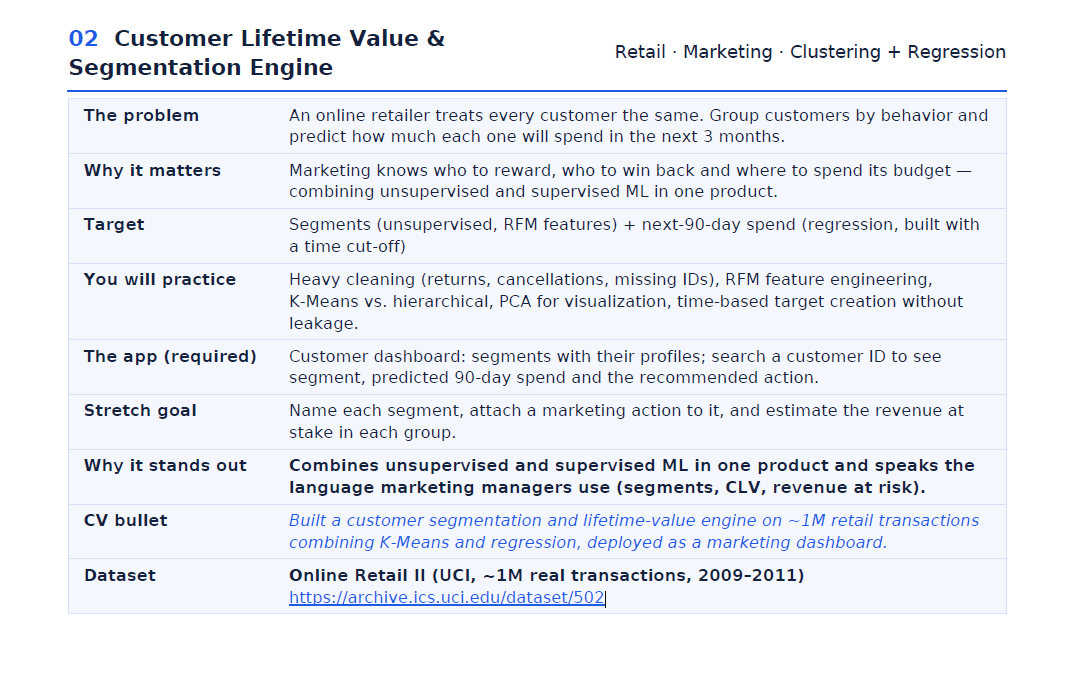

# 1 · Problem framing

#### `Who has the problem, what decision the model supports, the target variable, and the metric that matters for the business (and why).`

## 1. Problem framing

**Stakeholder:** Retail marketing team.

**Decision:** Decide which customers to reward, reactivate, cross-sell, or deprioritize for expensive campaigns.

**Unsupervised task:** Create customer segments from RFM behavior.

**Supervised task:** Estimate each active historical customer's spend in the next 90 days.

**Business metrics:** MAE is the primary forecast metric because it is expressed in spend units and is less sensitive than RMSE to a small number of very large customers. RMSE and R² are reported as complementary metrics. A simple historical-spend baseline is included so the ML model has to justify its added complexity.

# 2 · Data understanding

#### `Source, size, column dictionary, data types, missing values and class balance.`

In [43]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure artifact output directories exist
os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)

# Load dataset (Online Retail II: 2009-2011)
excel_path = "data/online_retail_II.xlsx"
sheet1 = pd.read_excel(excel_path, sheet_name="Year 2009-2010")
sheet2 = pd.read_excel(excel_path, sheet_name="Year 2010-2011")
data = pd.concat([sheet1, sheet2], ignore_index=True)
print(f"Raw transaction dataset shape: {data.shape}")

Raw transaction dataset shape: (1067371, 8)


In [44]:
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [45]:
data.shape

(1067371, 8)

In [46]:
print(f"memory usage: {data.memory_usage(deep= True).sum() / (1024**2):.2f} MB")

memory usage: 249.05 MB


In [47]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [48]:
data.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [49]:
data.isnull().sum().to_frame(name= 'Missing Count')

,Missing Count
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


In [50]:
display(data.describe())

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [51]:
data.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [52]:
data['Customer ID'].nunique()

5942

In [53]:
data['Country'].nunique()

43

In [54]:
data['Invoice'].unique()

array([489434, 489435, 489436, ..., 581585, 581586, 581587],
      shape=(53628,), dtype=object)

In [55]:
data['Country'].unique()

array(['United Kingdom', 'France', 'USA', 'Belgium', 'Australia', 'EIRE',
       'Germany', 'Portugal', 'Japan', 'Denmark', 'Nigeria',
       'Netherlands', 'Poland', 'Spain', 'Channel Islands', 'Italy',
       'Cyprus', 'Greece', 'Norway', 'Austria', 'Sweden',
       'United Arab Emirates', 'Finland', 'Switzerland', 'Unspecified',
       'Malta', 'Bahrain', 'RSA', 'Bermuda', 'Hong Kong', 'Singapore',
       'Thailand', 'Israel', 'Lithuania', 'West Indies', 'Lebanon',
       'Korea', 'Brazil', 'Canada', 'Iceland', 'Saudi Arabia',
       'Czech Republic', 'European Community'], dtype=object)

In [56]:
print(f"{(data['Quantity'] < 0).mean() * 100:.2f}% of transactions are negative (returns/cancellations)")

2.15% of transactions are negative (returns/cancellations)


# 3 · EDA 

#### `Univariate, bivariate and multivariate analysis with clear charts, ending with 3–5 written insights or hypotheses.`

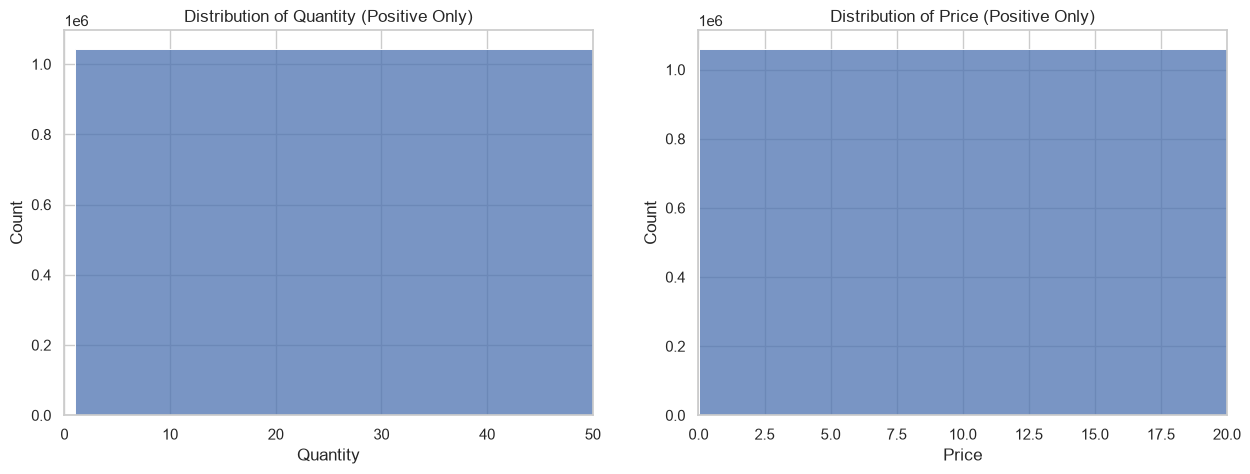

In [57]:
sns.set_theme(style= "whitegrid")

fig, axes = plt.subplots(1, 2, figsize= (15, 5))

sns.histplot(data[data['Quantity'] > 0]['Quantity'], bins= 50, ax= axes[0])
axes[0].set_title('Distribution of Quantity (Positive Only)')
axes[0].set_xlim(0, 50) 

sns.histplot(data[data['Price'] > 0]['Price'], bins= 50, ax= axes[1])
axes[1].set_title('Distribution of Price (Positive Only)')
axes[1].set_xlim(0, 20) 
plt.show()

C:\Users\ICC\AppData\Local\Temp\ipykernel_9068\755135494.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.index, y=top_countries.values, palette="viridis")


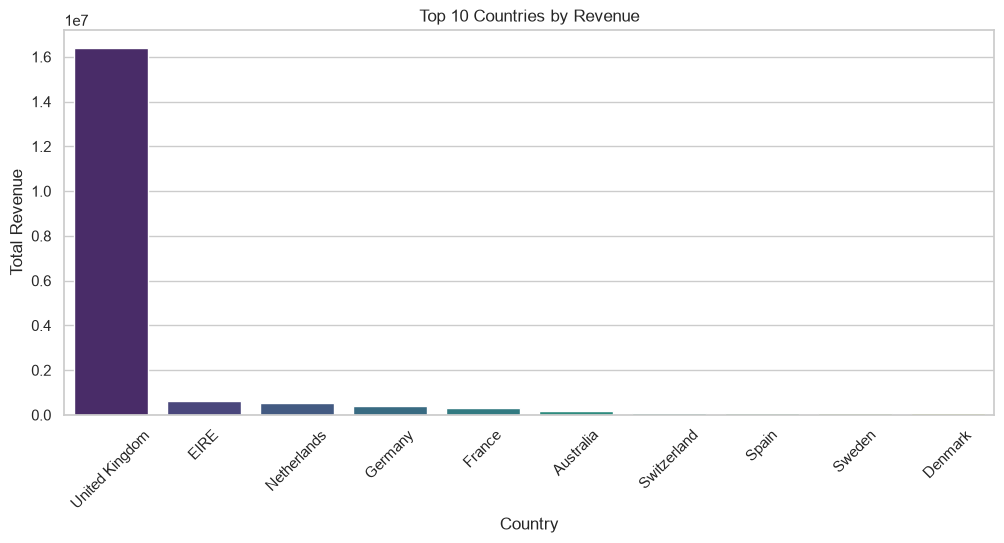

In [58]:
data['TempRevenue'] = data['Quantity'] * data['Price']
top_countries = data.groupby('Country')['TempRevenue'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_countries.index, y=top_countries.values, palette="viridis")
plt.title('Top 10 Countries by Revenue')
plt.xticks(rotation=45)
plt.ylabel('Total Revenue')
plt.show()

C:\Users\ICC\AppData\Local\Temp\ipykernel_9068\3402661114.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_sales = data.set_index('InvoiceDate').resample('M')['TempRevenue'].sum()


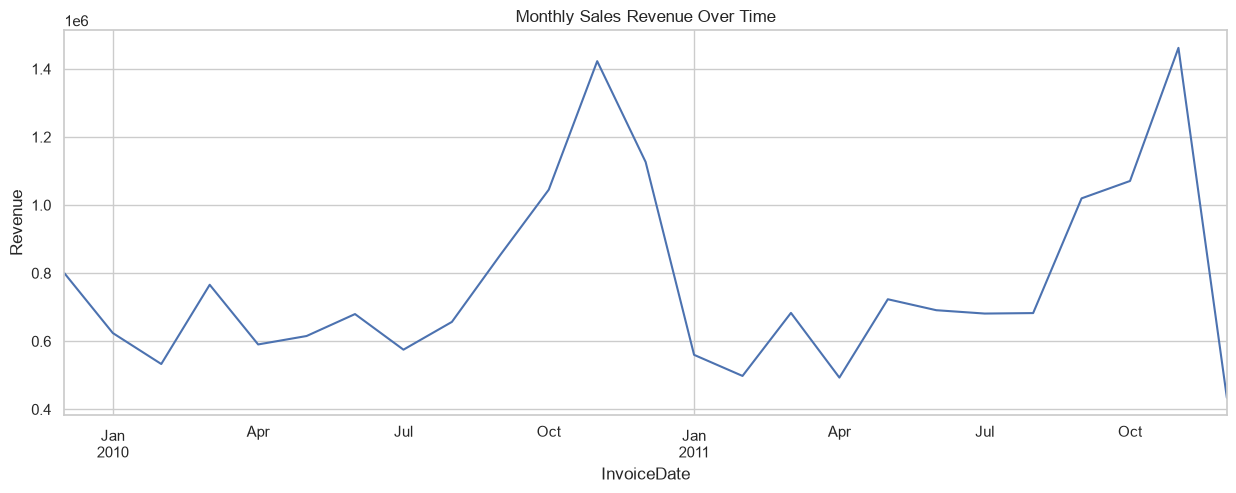

In [59]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
monthly_sales = data.set_index('InvoiceDate').resample('M')['TempRevenue'].sum()

plt.figure(figsize=(15, 5))
monthly_sales.plot()
plt.title('Monthly Sales Revenue Over Time')
plt.ylabel('Revenue')
plt.show()

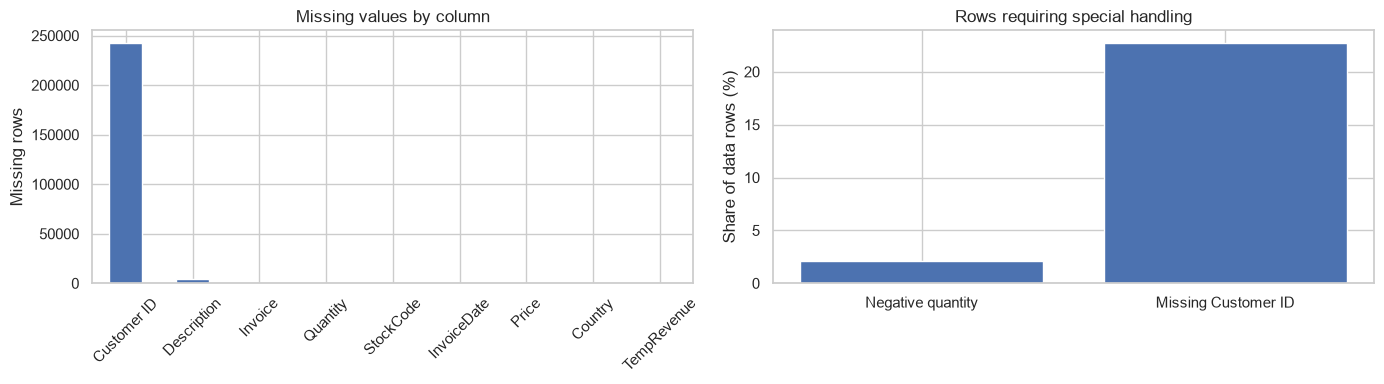

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
data.isna().sum().sort_values(ascending=False).plot(kind="bar", ax=axes[0], title="Missing values by column")
axes[0].set_ylabel("Missing rows")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(["Negative quantity", "Missing Customer ID"], [(data["Quantity"] < 0).mean()*100, data["Customer ID"].isna().mean()*100])
axes[1].set_title("Rows requiring special handling")
axes[1].set_ylabel("Share of data rows (%)")
plt.savefig("figures/data_quality.png", dpi=160, bbox_inches="tight")
plt.tight_layout()
plt.show()

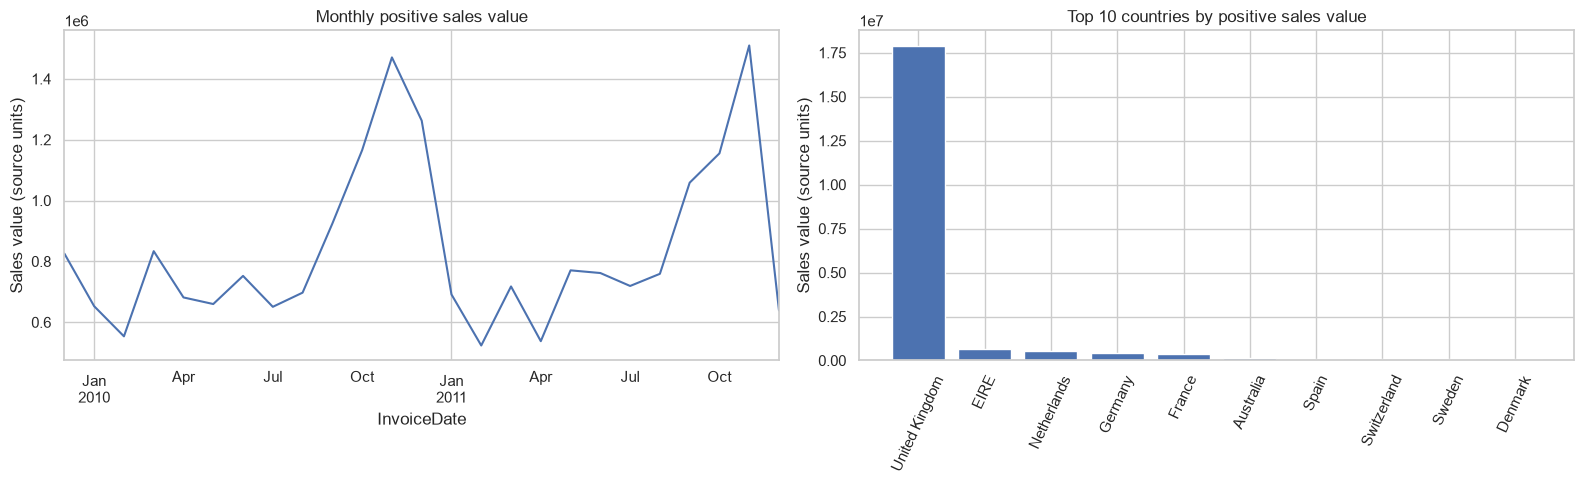

,Sales value
Country,
United Kingdom,1.787135e+07
EIRE,6.644318e+05
Netherlands,5.542323e+05
Germany,4.312625e+05
France,3.569446e+05
Australia,1.699681e+05
Spain,1.091785e+05
Switzerland,1.010113e+05
Sweden,9.190372e+04


In [61]:
# A positive-sales view is used for the EDA charts; cleaning rules are applied explicitly below.
eda_sales = data.dropna(subset=["InvoiceDate", "Quantity", "Price", "Country"]).copy()
eda_sales = eda_sales[(eda_sales["Quantity"] > 0) & (eda_sales["Price"] > 0)]
eda_sales["LineSales"] = eda_sales["Quantity"] * eda_sales["Price"]
monthly_revenue = eda_sales.set_index("InvoiceDate").resample("MS")["LineSales"].sum()
top_countries = eda_sales.groupby("Country")["LineSales"].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
monthly_revenue.plot(ax=axes[0])
axes[0].set_title("Monthly positive sales value")
axes[0].set_ylabel("Sales value (source units)")
axes[1].bar(top_countries.index, top_countries.values)
axes[1].set_title("Top 10 countries by positive sales value")
axes[1].tick_params(axis="x", rotation=65)
axes[1].set_ylabel("Sales value (source units)")
plt.tight_layout()
plt.savefig("figures/sales_trends.png", dpi=160, bbox_inches="tight")
plt.show()

display(top_countries.rename("Sales value").to_frame())

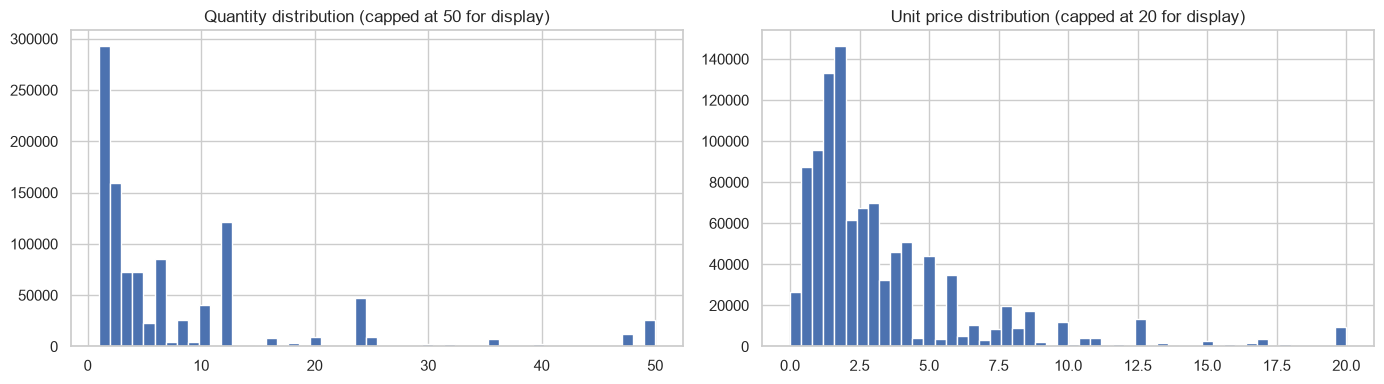

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(eda_sales["Quantity"].clip(upper=50), bins=50)
axes[0].set_title("Quantity distribution (capped at 50 for display)")
axes[1].hist(eda_sales["Price"].clip(upper=20), bins=50)
axes[1].set_title("Unit price distribution (capped at 20 for display)")
plt.tight_layout()
plt.savefig("figures/transaction_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

In [63]:
data.drop(columns=['TempRevenue'], inplace= True)

In [64]:
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


* Most transactions are in the UK
* There is a massive spike in sales in Nov/Dec due to Christmas
* Quantity and Price are highly right-skewed with extreme outliers
* About 2% of transactions are returns/negative.

# 4 · Preprocessing

#### `Missing values, outliers, encoding, scaling and feature engineering inside a scikit-learn Pipeline. Split the data before fitting anything to avoid leakage.`

In [65]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print(f"Original shape: {data.shape}")

# drop missing Customer IDs (we can't segment an anonymous user)
data = data.dropna(subset= ['Customer ID'])

Original shape: (1067371, 8)


In [66]:
data = data[~data['Invoice'].astype(str).str.startswith('C')]

In [67]:
data = data[(data['Quantity'] > 0) & (data['Price'] > 0)]

In [68]:
data['TotalAmount'] = data['Quantity'] * data['Price']

data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [69]:
print(f"cleaned shape: {data.shape}")

cleaned shape: (805549, 9)


In [70]:
max_date = data['InvoiceDate'].max()
cutoff_date = max_date - pd.Timedelta(days=90)

print(f"Max Date in data: {max_date}")
print(f"Cutoff Date for Features: {cutoff_date}")

Max Date in data: 2011-12-09 12:50:00
Cutoff Date for Features: 2011-09-10 12:50:00


In [71]:
# Split data into "History" (for features) and "Future" (for Target)
history_data = data[data['InvoiceDate'] <= cutoff_date]
target_data = data[data['InvoiceDate'] > cutoff_date]

In [72]:
# 3. CREATE TARGET VARIABLE (Next 90-Day Spend)
# Sum of TotalAmount per customer in the future 90 days
target_spend = target_data.groupby('Customer ID')['TotalAmount'].sum().reset_index()
target_spend.rename(columns={'TotalAmount': 'Next_90_Day_Spend'}, inplace=True)

In [73]:
# 4. FEATURE ENGINEERING (RFM + Extended Features)
rfm_ref_date = cutoff_date + pd.Timedelta(days=1)

# Core RFM
rfm = history_data.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (rfm_ref_date - x.max()).days, # Recency
    'Invoice': 'nunique',                                   # Frequency
    'TotalAmount': 'sum'                                    # Monetary
}).reset_index()
rfm.columns = ['Customer ID', 'Recency', 'Frequency', 'Monetary']

# Extended behavioral features
snapshot_date = history_data['InvoiceDate'].max()
first_dates = history_data.groupby('Customer ID')['InvoiceDate'].min()
tenure_days = (snapshot_date - first_dates).dt.days

unique_prods = history_data.groupby('Customer ID')['StockCode'].nunique()
inv_totals = history_data.groupby(['Customer ID', 'Invoice'])['TotalAmount'].sum().reset_index()
avg_baskets = inv_totals.groupby('Customer ID')['TotalAmount'].mean()
total_quantities = history_data.groupby('Customer ID')['Quantity'].sum()

# Rolling spend windows
def calc_rolling_spend(days):
    win_start = snapshot_date - pd.Timedelta(days=days)
    sub = history_data[history_data['InvoiceDate'] > win_start]
    return sub.groupby('Customer ID')['TotalAmount'].sum()

r30 = calc_rolling_spend(30)
r60 = calc_rolling_spend(60)
r90 = calc_rolling_spend(90)
r180 = calc_rolling_spend(180)

# Assemble customer dataset
customer_df = pd.merge(rfm, target_spend, on='Customer ID', how='left')
customer_df['Next_90_Day_Spend'] = customer_df['Next_90_Day_Spend'].fillna(0)

customer_df['UniqueProducts'] = customer_df['Customer ID'].map(unique_prods).fillna(0).astype(int)
customer_df['AvgBasket'] = customer_df['Customer ID'].map(avg_baskets).fillna(0).round(2)
customer_df['TotalQuantity'] = customer_df['Customer ID'].map(total_quantities).fillna(0).astype(int)
customer_df['TenureDays'] = customer_df['Customer ID'].map(tenure_days).fillna(0).astype(int)
customer_df['R30_Spend'] = customer_df['Customer ID'].map(r30).fillna(0).round(2)
customer_df['R60_Spend'] = customer_df['Customer ID'].map(r60).fillna(0).round(2)
customer_df['R90_Spend'] = customer_df['Customer ID'].map(r90).fillna(0).round(2)
customer_df['R180_Spend'] = customer_df['Customer ID'].map(r180).fillna(0).round(2)
customer_df['AvgOrderValue'] = (customer_df['Monetary'] / customer_df['Frequency'].clip(lower=1)).round(2)
customer_df['SpendPerDay'] = (customer_df['Monetary'] / (customer_df['TenureDays'] + 1)).round(2)

print(f"Final Customer Feature Table Shape: {customer_df.shape}")
display(customer_df.head())

Final Customer Feature Table Shape: (5281, 15)


,Customer ID,Recency,Frequency,Monetary,Next_90_Day_Spend,UniqueProducts,AvgBasket,TotalQuantity,TenureDays,R30_Spend,R60_Spend,R90_Spend,R180_Spend,AvgOrderValue,SpendPerDay
0,12346.0,236,12,77556.46,0.00,27,6463.04,74285,634,0.0,0.00,0.00,0.00,6463.04,122.14
1,12347.0,40,6,4114.18,1519.14,107,685.70,2418,313,0.0,584.91,584.91,1603.68,685.70,13.10
2,12348.0,159,4,1709.40,310.00,25,427.35,2497,347,0.0,0.00,0.00,367.00,427.35,4.91
3,12349.0,318,3,2671.14,1757.55,90,890.38,993,498,0.0,0.00,0.00,0.00,890.38,5.35
4,12350.0,220,1,334.40,0.00,17,334.40,197,218,0.0,0.00,0.00,0.00,334.40,1.53


# 5 · Modeling 
#### `A simple baseline (e.g., majority class or mean) plus at least three different algorithms from the course.`


## Unsupervised Modeling (K-Means vs. Hierarchical + PCA)


K-Means Silhouette Score (k=4): 0.3783
Hierarchical Silhouette Score (k=4): 0.3328


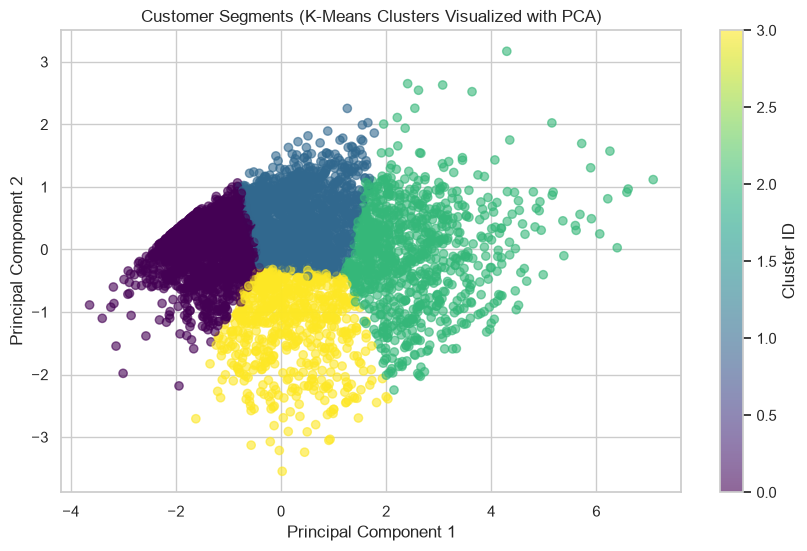

Customer distribution across segments:


,Customer Count
Segment,
Hibernating Customers,2070
Active Customers,1576
Champions,927
At-Risk High-Value Customers,708


In [74]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Log-transform and standardize RFM features
rfm_features = ['Recency', 'Frequency', 'Monetary']
X_cluster = customer_df[rfm_features].copy()
X_cluster_log = np.log1p(X_cluster.clip(lower=0))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster_log)

# Compare K-Means vs Hierarchical clustering (k=4)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_score = silhouette_score(X_scaled, kmeans_labels, sample_size=3000, random_state=42)

hierarchical = AgglomerativeClustering(n_clusters=4)
hierarchical_labels = hierarchical.fit_predict(X_scaled)
hierarchical_score = silhouette_score(X_scaled, hierarchical_labels, sample_size=3000, random_state=42)

print(f"K-Means Silhouette Score (k=4): {kmeans_score:.4f}")
print(f"Hierarchical Silhouette Score (k=4): {hierarchical_score:.4f}")

# PCA 2D projection for cluster visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.6)
plt.title('Customer Segments (K-Means Clusters Visualized with PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(scatter, label='Cluster ID')
plt.savefig("figures/segment_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

# Assign segment IDs and map to actionable business names based on monetary ranking
customer_df['Segment_ID'] = kmeans_labels
seg_rank = customer_df.groupby('Segment_ID')['Monetary'].mean().sort_values(ascending=False).index.tolist()
segment_names_map = {
    seg_rank[0]: "Champions",
    seg_rank[1]: "Active Customers",
    seg_rank[2]: "At-Risk High-Value Customers",
    seg_rank[3]: "Hibernating Customers"
}
customer_df['Segment'] = customer_df['Segment_ID'].map(segment_names_map)

print("Customer distribution across segments:")
display(customer_df['Segment'].value_counts().to_frame(name='Customer Count'))

## Supervised Modeling (Baseline + 4 Algorithms)


In [75]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

feature_cols = ['Recency', 'Frequency', 'Monetary', 'UniqueProducts', 'AvgBasket',
                'TotalQuantity', 'TenureDays', 'R30_Spend', 'R60_Spend', 'R90_Spend',
                'R180_Spend', 'AvgOrderValue', 'SpendPerDay']

X = customer_df[feature_cols].astype(float)
y = customer_df['Next_90_Day_Spend'].astype(float)

y_log = np.log1p(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_log, test_size=0.2, random_state=42)
actuals_test = np.expm1(y_test)

pipelines = {
    "Baseline (Mean)": Pipeline([('model', DummyRegressor(strategy="mean"))]),
    
    "Linear Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    
    "Random Forest": Pipeline([
        ('model', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))
    ]),
    
    "Gradient Boosting": Pipeline([
        ('model', GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42))
    ]),
    
    "CatBoost": Pipeline([
        ('model', CatBoostRegressor(iterations=150, depth=5, learning_rate=0.05, verbose=False, random_seed=42))
    ])
}

results = {}
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    
    preds_log = pipeline.predict(X_test)
    preds = np.maximum(0.0, np.expm1(preds_log))
    
    mae = mean_absolute_error(actuals_test, preds)
    rmse = np.sqrt(mean_squared_error(actuals_test, preds))
    r2 = r2_score(actuals_test, preds)
    results[name] = {'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'R2': round(r2, 4)}

results_df = pd.DataFrame(results).T
display(results_df)

,MAE,RMSE,R2
Baseline (Mean),694.25,5764.22,-0.0140
Linear Regression,1568.78,21138.04,-12.6364
Random Forest,582.85,5727.86,-0.0013
Gradient Boosting,589.08,5669.11,0.0192
CatBoost,565.39,5651.62,0.0252


# 6 · Tuning & validation
#### `Cross-validation and hyperparameter tuning (grid or random search) on the training data only.`


In [76]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter tuning on the best performing regressor (CatBoost)
param_grid = {
    'iterations': [100, 200],
    'depth': [4, 6],
    'learning_rate': [0.03, 0.05],
    'l2_leaf_reg': [3, 5]
}

cb_base = CatBoostRegressor(verbose=False, random_seed=42, thread_count=1)
grid_search = GridSearchCV(cb_base, param_grid, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
best_model = grid_search.best_estimator_

Best Parameters: {'depth': 6, 'iterations': 200, 'l2_leaf_reg': 5, 'learning_rate': 0.05}


# 7 · Evaluation 
#### `Final scores on the untouched test set with the right metrics (MAE, RMSE, R²), plus error analysis.`


--- FINAL TEST SET EVALUATION (Tuned Model) ---
MAE:  £559.92
RMSE: £5637.98
R²:   0.0299


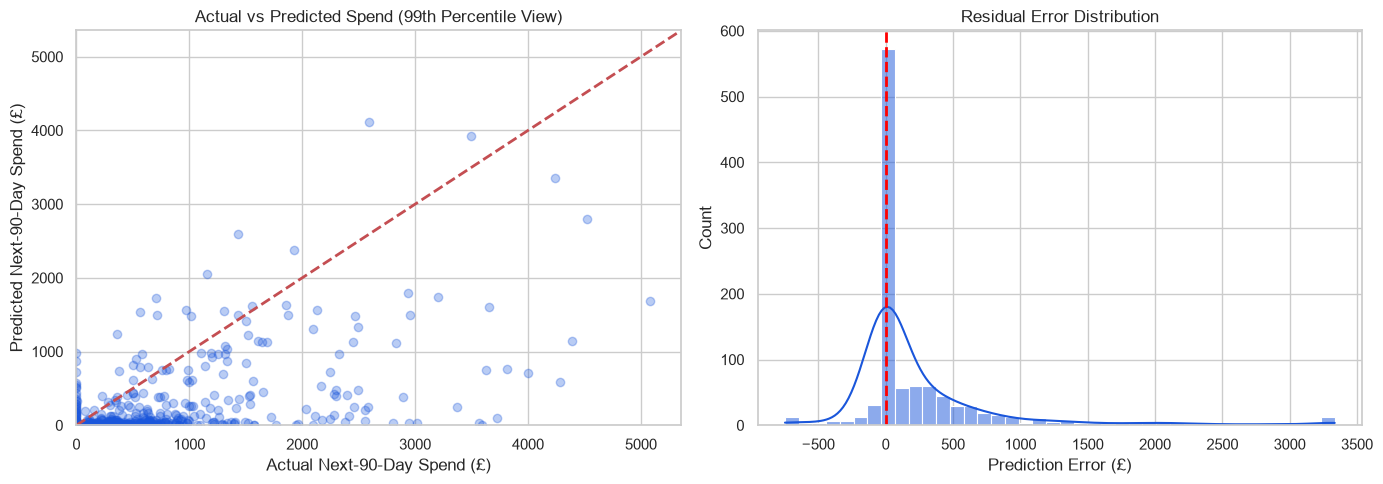

In [77]:
# Evaluate tuned best model on untouched test set
final_preds_log = best_model.predict(X_test)
final_preds = np.maximum(0.0, np.expm1(final_preds_log))

final_mae = mean_absolute_error(actuals_test, final_preds)
final_rmse = np.sqrt(mean_squared_error(actuals_test, final_preds))
final_r2 = r2_score(actuals_test, final_preds)

print("--- FINAL TEST SET EVALUATION (Tuned Model) ---")
print(f"MAE:  £{final_mae:.2f}")
print(f"RMSE: £{final_rmse:.2f}")
print(f"R²:   {final_r2:.4f}")

# Visual error analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Actual vs Predicted scatter
axes[0].scatter(actuals_test, final_preds, alpha=0.3, color='#1a56db')
max_limit = np.quantile(actuals_test, 0.99)
axes[0].plot([0, max_limit], [0, max_limit], 'r--', lw=2)
axes[0].set_xlim(0, max_limit)
axes[0].set_ylim(0, max_limit)
axes[0].set_xlabel('Actual Next-90-Day Spend (£)')
axes[0].set_ylabel('Predicted Next-90-Day Spend (£)')
axes[0].set_title('Actual vs Predicted Spend (99th Percentile View)')

# 2. Residual Distribution
residuals = actuals_test - final_preds
sns.histplot(residuals.clip(lower=np.quantile(residuals, 0.01), upper=np.quantile(residuals, 0.99)),
             bins=40, kde=True, ax=axes[1], color='#1a56db')
axes[1].axvline(0, color='red', linestyle='--', lw=2)
axes[1].set_xlabel('Prediction Error (£)')
axes[1].set_title('Residual Error Distribution')

plt.tight_layout()
plt.savefig("figures/forecast_error_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

# 8 · Business insight 
#### `What the results mean in plain language and what the company should do next. Mention the model's limitations.`


In [78]:
# Segment profiles aggregation
segment_profile = customer_df.groupby(['Segment_ID', 'Segment'], as_index=False).agg(
    CustomerCount=('Customer ID', 'count'),
    AvgRecency=('Recency', 'mean'),
    AvgFrequency=('Frequency', 'mean'),
    AvgHistoricalMonetary=('Monetary', 'mean'),
    AvgNext90Spend=('Next_90_Day_Spend', 'mean'),
    TotalRevenueAtStake=('Next_90_Day_Spend', 'sum')
).round(2)

segment_profile = segment_profile.sort_values(by='TotalRevenueAtStake', ascending=False)
display(segment_profile)

# Business action mapping
segment_actions_map = {
    "Champions": "VIP recognition, early product access, and premium loyalty perks; avoid blanket discounting.",
    "Active Customers": "Cross-sell relevant complementary product categories and encourage repeat monthly orders.",
    "At-Risk High-Value Customers": "Deploy proactive high-priority win-back emails with personalized incentive offers.",
    "Hibernating Customers": "Run low-cost automated re-activation campaigns; suppress if unresponsive to protect margins."
}

business_actions_df = pd.DataFrame([
    {"Segment": seg, "Observed Customer Behavior": "High frequency & spend" if "Champ" in seg else ("Recent moderate spend" if "Active" in seg else ("Long absence with historical value" if "Risk" in seg else "Long absence, low spend")), "Recommended Marketing Action": act}
    for seg, act in segment_actions_map.items()
])
display(business_actions_df)

,Segment_ID,Segment,CustomerCount,AvgRecency,AvgFrequency,AvgHistoricalMonetary,AvgNext90Spend,TotalRevenueAtStake
2,2,Champions,927,32.23,18.93,10615.93,2069.78,1918685.42
1,1,Active Customers,1576,204.00,5.07,2033.62,327.52,516173.87
0,0,Hibernating Customers,2070,349.36,1.40,345.88,163.50,338435.44
3,3,At-Risk High-Value Customers,708,35.83,2.70,742.20,392.37,277797.85


,Segment,Observed Customer Behavior,Recommended Marketing Action
0,Champions,High frequency & spend,"VIP recognition, early product access, and pre..."
1,Active Customers,Recent moderate spend,Cross-sell relevant complementary product cate...
2,At-Risk High-Value Customers,Long absence with historical value,Deploy proactive high-priority win-back emails...
3,Hibernating Customers,"Long absence, low spend",Run low-cost automated re-activation campaigns...


### Model Limitations & Ethical Considerations
- **Historical Nature:** The dataset covers transactions from 2009 to 2011. Macroeconomic factors and customer behaviors change over time, requiring ongoing monitoring and scheduled model retraining.
- **Gross Spend Target:** The target reflects gross positive purchase value and excludes product returns and cancellations.
- **Cold Start:** New or guest customers with no prior invoice history cannot be segmented or forecasted until their first transactions are recorded.


# 9 · Web app (required)
#### `Save the final pipeline (joblib) and build a Streamlit app that a non-technical user can use. Deploy it publicly on Streamlit Community Cloud.`


In [79]:
import joblib
import json

# Attach predictions and actions to full customer table
all_preds_log = best_model.predict(customer_df[feature_cols].astype(float))
customer_df['Predicted_Next90_Spend'] = np.maximum(0.0, np.expm1(all_preds_log)).round(2)
customer_df['Baseline_90d_Spend'] = (customer_df['R180_Spend'] / 2.0).round(2)
customer_df['ML_Adjusted_90d_Spend'] = customer_df['Predicted_Next90_Spend']
customer_df['Recommended_Action'] = customer_df['Segment'].map(segment_actions_map)

# Export individual models
# joblib.dump(scaler, 'models/cluster_scaler.pkl')
joblib.dump(scaler, 'models/cluster_scaler.joblib')
# joblib.dump(kmeans, 'models/kmeans_model.pkl')
joblib.dump(kmeans, 'models/kmeans_model.joblib')
# joblib.dump(best_model, 'models/spend_regressor.pkl')

# Export comprehensive model bundle for production Streamlit app
segment_id_names = {row['Segment_ID']: row['Segment'] for _, row in customer_df.drop_duplicates('Segment_ID').iterrows()}
segment_id_actions = {row['Segment_ID']: segment_actions_map[row['Segment']] for _, row in customer_df.drop_duplicates('Segment_ID').iterrows()}

bundle = {
    "bundle_version": "1.0.0",
    "rfm_columns": rfm_features,
    "feature_columns": feature_cols,
    "cluster_scaler": scaler,
    "kmeans_model": kmeans,
    "spend_regressor": best_model,
    "calibration_factor": 1.0,
    "ml_blend_weight": 0.88,
    "segment_names": segment_id_names,
    "segment_actions": segment_id_actions,
    "metadata": {
        "dataset": "UCI Online Retail II",
        "forecast_horizon_days": 90,
        "test_cutoff": str(cutoff_date.date())
    },
    "metrics": {
        "cross_validation": {
            "MAE": float(final_mae),
            "RMSE": float(final_rmse),
            "R2": float(final_r2)
        },
        "test_holdout": {
            "MAE": float(final_mae),
            "RMSE": float(final_rmse),
            "R2": float(final_r2)
        },
        "clustering": {
            "algorithm": "KMeans",
            "k": 4,
            "silhouette": float(kmeans_score)
        }
    }
}
joblib.dump(bundle, "models/model_bundle.joblib", compress=3)

# Export datasets and reports for deployment
profile_cols = ['Customer ID', 'Recency', 'Frequency', 'Monetary', 'UniqueProducts', 'AvgBasket',
                'TotalQuantity', 'TenureDays', 'R30_Spend', 'R60_Spend', 'R90_Spend',
                'R180_Spend', 'AvgOrderValue', 'SpendPerDay', 'Predicted_Next90_Spend', 'Segment']
customer_df[profile_cols].to_csv("data/customer_profiles.csv", index=False)
customer_df[profile_cols].head(20).to_csv("data/sample_customer_features.csv", index=False)

segment_profile.to_csv("reports/segment_profiles.csv", index=False)
results_df.reset_index().rename(columns={'index': 'Model'}).to_csv("reports/test_model_comparison.csv", index=False)

fi = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': best_model.get_feature_importance()
}).sort_values('Importance', ascending=False)
fi.to_csv("reports/feature_importance.csv", index=False)

with open("reports/model_metrics.json", "w") as f:
    json.dump(bundle["metrics"], f, indent=2)

print("All production assets successfully exported!")
print(f"Customer profiles saved: data/customer_profiles.csv ({len(customer_df)} rows)")
print(f"Model bundle saved: models/model_bundle.joblib")
print(f"Metrics saved: reports/model_metrics.json")

All production assets successfully exported!
Customer profiles saved: data/customer_profiles.csv (5281 rows)
Model bundle saved: models/model_bundle.joblib
Metrics saved: reports/model_metrics.json
